In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output

In [4]:
class BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.GroupNorm(32, 64), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GroupNorm(32, 128), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.GroupNorm(32, 256), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.GroupNorm(32, 512), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        
        self.time_mlp = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128)
        )
        
        self.fc = nn.Linear(512 + 128, 2)

    def forward(self, x, t):
        img_feats = self.features(x)
        
        if t.dim() == 1:
            t = t.unsqueeze(-1).float()
            
        time_feats = self.time_mlp(t)
        
        combined = torch.cat([img_feats, time_feats], dim=1)
        return self.fc(combined)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, groups=8):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),  # GroupNorm is standard for Diffusion
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class uNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input = DoubleConv(1, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(384, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(192, 128)

        self.output = nn.Conv2d(128, 1, kernel_size=1)

        self.emb_down1 = nn.Linear(time_dim, 128)
        self.emb_down2 = nn.Linear(time_dim, 256)
        self.emb_up1 = nn.Linear(time_dim, 256)
        self.emb_up2 = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        t = t.view(-1, 1) 
        emb = self.time_mlp(t)
        
        x1 = self.input(x)
        
        x2 = self.down1(x1)
        x2 = x2 + self.emb_down1(emb)[:, :, None, None]
        
        x3 = self.down2(x2)
        x3 = x3 + self.emb_down2(emb)[:, :, None, None]

        x_mid = self.bottleneck(x3)

        x_up1 = self.up1(x_mid)
        x_up1 = torch.cat([x_up1, x2], dim=1)
        x_up1 = self.conv_up1(x_up1) 
        x_up1 = x_up1 + self.emb_up1(emb)[:, :, None, None]
        
        x_up2 = self.up2(x_up1)
        x_up2 = torch.cat([x_up2, x1], dim=1)
        x_up2 = self.conv_up2(x_up2)
        x_up2 = x_up2 + self.emb_up2(emb)[:, :, None, None]

        return self.output(x_up2)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
biCls = BinaryClassifier().to(device)
cls = Classifier().to(device)
model = uNet().to(device)

biCls.load_state_dict(torch.load("8_binary_clsf.pth", map_location=device))
cls.load_state_dict(torch.load("mnist_cnn_wei.pth", map_location=device))
model.load_state_dict(torch.load("uncond_diff_wei.pth", map_location=device))

<All keys matched successfully>

In [6]:
img_size = 28
batch_size = 128
epochs = 100
timesteps = 500
img_size = 28

beta = torch.linspace(1e-4, 0.02, timesteps).to(device)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

In [7]:
# n_samples = 500
# s = 0
# final = []
# s_values = [0, 0.5, 1, 1.5, 2, 2.5]

# for i in range(5):
    
#     final_outputs = []
#     for s in s_values:
#         with torch.no_grad():
#             xt = torch.randn(n_samples, 1, img_size, img_size).to(device)
            
#             for i in reversed(range(timesteps)):
#                 # print(i)
#                 t = torch.tensor([i] * n_samples, device=device)
                
#                 eps_pred = model(xt, t.float() / timesteps)
                
#                 alpha_t = alpha[i]
#                 alpha_bar_t = alpha_bar[i]
#                 beta_t = beta[i]
        
#                 mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)
        
#                 with torch.enable_grad():
#                     dre_xt = xt.detach().clone().requires_grad_(True)
                    
#                     logits = biCls(dre_xt, t) 
#                     log_probs = F.log_softmax(logits, dim=1)
                    
#                     r = log_probs[:, 1] - log_probs[:, 0]
                    
#                     guide_score = torch.autograd.grad(
#                         outputs=r.sum(),
#                         inputs=dre_xt
#                     )[0]
                    
#                 mean = mean + s * beta_t * guide_score
                
#                 if i > 0:
#                     noise = torch.randn_like(xt)
#                     xt = mean + torch.sqrt(beta_t) * noise
#                 else:
#                     xt = mean
#         print("s: {} complete", s)
#         final_outputs.append((s, xt))
#     final.append(final_outputs)

2


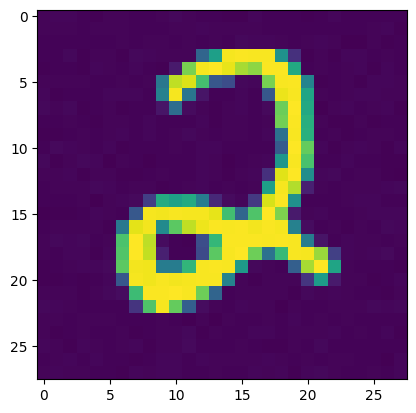

In [8]:
# torch.save(final, "5_runs_of_500_samples_of_5_guidance_strengths.pt")
final = torch.load("5_runs_of_500_samples_of_5_guidance_strengths.pt")

test_image = final[0][0][1][4][0].cpu()
plt.imshow(test_image)

print(cls(test_image[None, None, :, :].cuda()).argmax().cpu().item())

In [9]:
transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

idx = (dataset.targets == 8).nonzero(as_tuple=True)[0]

real_images = torch.stack([
    dataset[i][0] for i in idx
]).to(device)

real_images.shape

torch.Size([974, 1, 28, 28])

In [10]:
# for s, fake_images in final[0]:
#     print(fake_images)
#     fake_feats = cls.features(fake_images)
#     break

In [11]:
def knn_radius(features, k=3):
    dists = torch.cdist(features, features)
    dists.fill_diagonal_(float("inf"))
    return dists.kthvalue(k, dim=1).values


def precision(real_feats, fake_feats, r_real):
    d = torch.cdist(fake_feats, real_feats)
    return (d <= r_real.unsqueeze(0)).any(dim=1).float().mean().item()


def recall(real_feats, fake_feats, r_fake):
    d = torch.cdist(real_feats, fake_feats)
    return (d <= r_fake.unsqueeze(0)).any(dim=1).float().mean().item()

import torch
import numpy as np
from scipy import linalg

def compute_fid(real_feats, fake_feats, eps=1e-6):
    """
    real_feats, fake_feats: [N, D] torch tensors
    """
    real = real_feats.detach().cpu().numpy()
    fake = fake_feats.detach().cpu().numpy()

    mu_r = real.mean(axis=0)
    mu_f = fake.mean(axis=0)

    sigma_r = np.cov(real, rowvar=False)
    sigma_f = np.cov(fake, rowvar=False)

    diff = mu_r - mu_f

    covmean, _ = linalg.sqrtm(sigma_r @ sigma_f, disp=False)
    if not np.isfinite(covmean).all():
        covmean = linalg.sqrtm((sigma_r + eps*np.eye(sigma_r.shape[0])) @
                               (sigma_f + eps*np.eye(sigma_f.shape[0])))

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = diff @ diff + np.trace(sigma_r + sigma_f - 2 * covmean)
    return float(fid)


In [12]:
# experiments = []
# cls.eval()
# for experiment in final:
#     print("...")
#     metrics = []
#     for s, fake_images in experiment:
#         p, r, fid = 0, 0, 0
#         perm = torch.randperm(real_images.shape[0])[:500]
#         for i in range(10):
#             real_feats = cls.features(real_images[perm])
#             fake_feats = cls.features(fake_images)
            
#             r_real = knn_radius(real_feats)
#             r_fake = knn_radius(fake_feats)
            
#             p += precision(real_feats, fake_feats, r_real)
#             r += recall(real_feats, fake_feats, r_fake)
#             fid += compute_fid(real_feats, fake_feats)

#         fid /= 10
#         p /= 10
#         r /= 10
#         metrics.append((s, fid, p, r, (2 * p * r) / (p + r)))
#     experiments.append(metrics)

In [13]:
# experiments = []
# cls.eval()

# for experiment in final:
#     metrics = []
#     for s, fake_images in experiment:
#         fid = 0.0
#         perm = torch.randperm(real_images.shape[0])[:500]

#         for i in range(10):
#             real_feats = cls.features(real_images[perm])
#             fake_feats = cls.features(fake_images)

#             fid += compute_fid(real_feats, fake_feats)

#         fid /= 10
#         metrics.append((s, fid))

#     experiments.append(metrics)


In [14]:
steps = torch.tensor(experiments)[0,:,0]
values = torch.tensor(experiments)[:,:,1:]
n = values.shape[0]
mean_exp = values.mean(dim=0)
std_exp = values.std(dim=0, unbiased=True)
sem_exp = std_exp / (n ** 0.5) * 2.776
cls_fid = steps, mean_exp[:,0], sem_exp[:,0]
cls_pre = steps, mean_exp[:,1], sem_exp[:,1]
cls_rec = steps, mean_exp[:,2], sem_exp[:,2]
cls_f1 = steps, mean_exp[:,3], sem_exp[:,3]

NameError: name 'experiments' is not defined

In [22]:
cls_fid

(tensor([0.0000, 0.5000, 1.0000, 1.5000, 2.0000, 2.5000]),
 tensor([0.0055, 0.0042, 0.0067, 0.0103, 0.0138, 0.0156]),
 tensor([1.2421e-04, 6.5224e-05, 4.5615e-04, 6.5807e-04, 4.4125e-04, 1.0370e-03]))

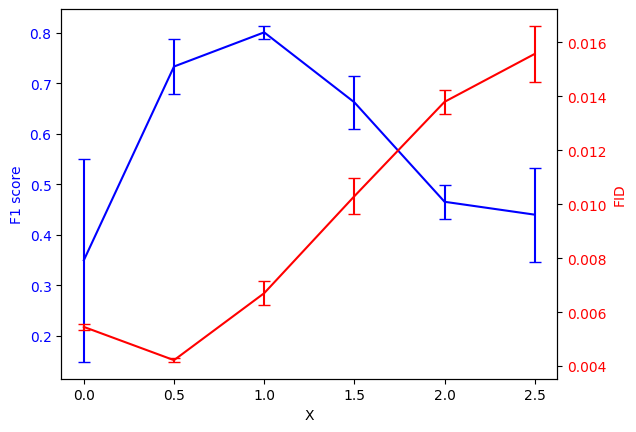

In [23]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots()

ax1.errorbar(
    cls_f1[0], cls_f1[1],
    yerr=cls_f1[2],
    capsize=4,
    color="blue",
    label="F1"
)
ax1.set_ylabel("F1 score", color="blue")
ax1.tick_params(axis='y', labelcolor="blue")

ax2 = ax1.twinx()

ax2.errorbar(
    cls_fid[0], cls_fid[1],
    yerr=cls_fid[2],
    capsize=4,
    color="red",
    label="FID"
)
ax2.set_ylabel("FID", color="red")
ax2.tick_params(axis='y', labelcolor="red")

ax1.set_xlabel("X")

plt.show()


<ErrorbarContainer object of 3 artists>

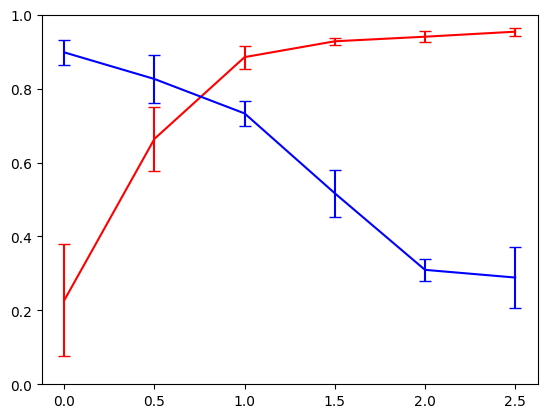

In [24]:
plt.ylim(0,1)
plt.errorbar(cls_pre[0], cls_pre[1], yerr=cls_pre[2], capsize=4, color="red")
plt.errorbar(cls_rec[0], cls_rec[1], yerr=cls_rec[2], capsize=4, color="blue")


In [15]:
# torch.save(experiments, "5_runs_of_500_samples_of_5_guidance_strengths_after_cls_gets_features.pt")
experiments = torch.load("5_runs_of_500_samples_of_5_guidance_strengths_after_cls_gets_features.pt")

In [20]:
steps = torch.tensor(experiments)[0,:,0]
values = torch.tensor(experiments)[:,:,1:]
n = values.shape[0]
mean_exp = values.mean(dim=0)
std_exp = values.std(dim=0, unbiased=True)
sem_exp = std_exp / (n ** 0.5) * 2.776

cls_prec = steps, mean_exp[:,0], sem_exp[:,0]
cls_rec = steps, mean_exp[:,1], sem_exp[:,1]
cls_f1 = steps, mean_exp[:,2], sem_exp[:,2]

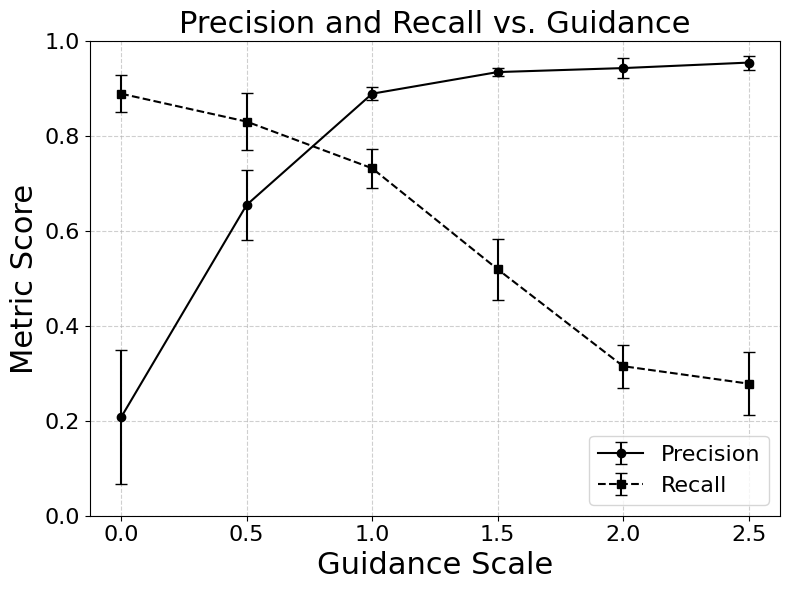

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Y-axis limits
plt.ylim(0, 1)

# Precision
plt.errorbar(
    cls_prec[0],
    cls_prec[1],
    yerr=cls_prec[2],
    fmt='o-',
    capsize=4,
    color='black',
    label='Precision'
)

# Recall
plt.errorbar(
    cls_rec[0],
    cls_rec[1],
    yerr=cls_rec[2],
    fmt='s--',
    capsize=4,
    color='black',
    label='Recall'
)

# Labels and title (larger text)
plt.xlabel('Guidance Scale', fontsize=22)
plt.ylabel('Metric Score', fontsize=22)
plt.title('Precision and Recall vs. Guidance', fontsize=22)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)

# Add grid
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

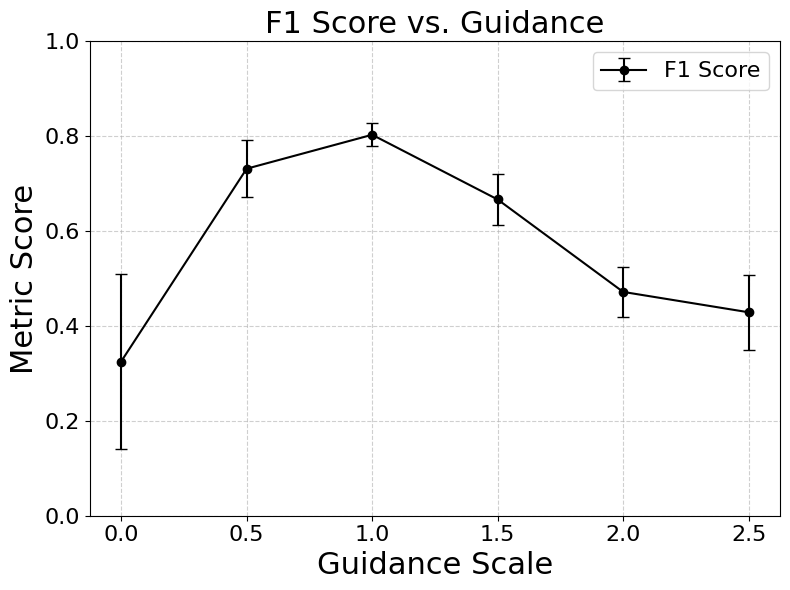

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Y-axis limits
plt.ylim(0, 1)

# F1 Score
plt.errorbar(
    cls_f1[0],
    cls_f1[1],
    yerr=cls_f1[2],
    fmt='o-',
    capsize=4,
    color='black',
    label='F1 Score'
)

plt.xlabel('Guidance Scale', fontsize=22)
plt.ylabel('Metric Score', fontsize=22)
plt.title('F1 Score vs. Guidance', fontsize=22)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)

# Grid
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [29]:
experiments = []
cls.eval()
for experiment in final:
    metrics = []
    for s, fake_images in experiment:
        p, r, = 0, 0
        perm = torch.randperm(real_images.shape[0])[:500]
        for i in range(10):
            real_feats = biCls.features(real_images[perm])
            fake_feats = biCls.features(fake_images)
            
            r_real = knn_radius(real_feats)
            r_fake = knn_radius(fake_feats)
            
            p += precision(real_feats, fake_feats, r_real)
            r += recall(real_feats, fake_feats, r_fake)

        p /= 10
        r /= 10
        metrics.append((s, p, r, (2 * p * r) / (p + r)))
    experiments.append(metrics)

In [30]:
steps = torch.tensor(experiments)[0,:,0]
values = torch.tensor(experiments)[:,:,1:]
n = values.shape[0]
mean_exp = values.mean(dim=0)
std_exp = values.std(dim=0, unbiased=True)
sem_exp = std_exp / (n ** 0.5) * 2.776

biCls_prec = steps, mean_exp[:,0], sem_exp[:,0]
biCls_rec = steps, mean_exp[:,1], sem_exp[:,1]
biCls_f1 = steps, mean_exp[:,2], sem_exp[:,2]

NameError: name 'biCls_prec' is not defined

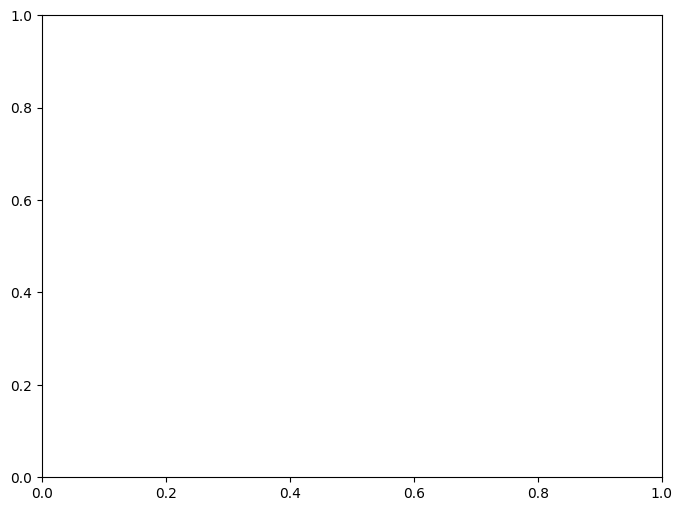

In [1]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Set y-axis limits
plt.ylim(0, 1)

# Precision (solid line with circle markers)
plt.errorbar(
    biCls_prec[0],          # x values (Guidance Scale)
    biCls_prec[1],          # precision means
    yerr=biCls_prec[2],     # precision CI
    fmt='o-',               # circle marker + solid line
    capsize=4,
    color='black',
    label='Precision'
)

# Recall (dashed line with square markers)
plt.errorbar(
    biCls_prec[0],          # same x values
    biCls_rec[1],           # recall means
    yerr=biCls_rec[2],      # recall CI
    fmt='s--',              # square marker + dashed line
    capsize=4,
    color='black',
    label='Recall'
)

# Labels and title
plt.xlabel('Guidance Scale')
plt.ylabel('Metric (95% Confidence Interval)')
plt.title('Precision vs. Recall')

# Legend
plt.legend()

plt.tight_layout()
plt.show()

<ErrorbarContainer object of 3 artists>

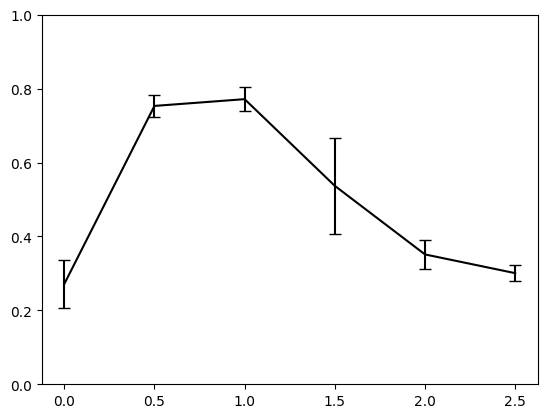

In [32]:
plt.ylim(0,1)
plt.errorbar(steps, mean_exp[:,2], yerr=sem_exp[:,2], capsize=4, color="black")

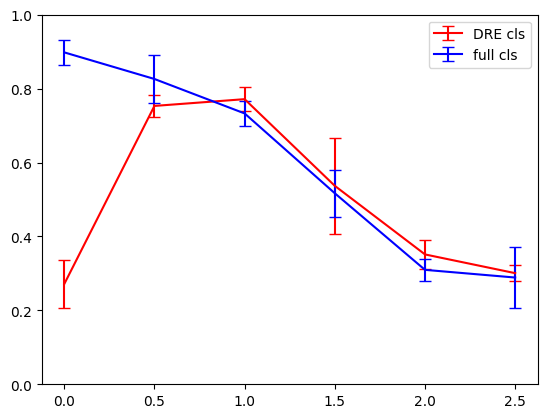

In [33]:
plt.ylim(0,1)
plt.errorbar(biCls_f1[0], biCls_f1[1], yerr=biCls_f1[2], capsize=4, color="red", label="DRE cls")
plt.errorbar(cls_f1[0], cls_f1[1], yerr=cls_f1[2], capsize=4, color="blue", label="full cls")
plt.legend()